# P6 – Scoring crédit « Prêt à dépenser »
## Notebook 03 : interprétabilité (SHAP)

**Objectif**
- **Global** : quelles variables pilotent les décisions du modèle ?
- **Local** : pour **un client donné**, pourquoi ce score ? (sert au dashboard)

**Principe** : la valeur SHAP d'une variable mesure combien elle *pousse* la prédiction
vers le haut (plus de risque) ou vers le bas (moins de risque) par rapport à un client moyen.
Pour LightGBM, `TreeExplainer` calcule ces valeurs de façon exacte et rapide.
Les valeurs sont exprimées en **log-odds** (échelle du modèle, pas en probabilité).

In [1]:
import gc
import json
import os
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

RAW_DIR = Path(
    os.environ.get(
        "P6_DATA_DIR",
        r"D:\Python_Datascience\Projet_OC6\Projet+Mise+en+prod+-+home-credit-default-risk",
    )
)
PROCESSED_DIR = RAW_DIR / "processed"
MODEL_DIR = Path("models")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

SEED = 42
N_SAMPLE = int(os.environ.get("P6_SHAP_SAMPLE", 5000))

model = lgb.Booster(model_file=str(MODEL_DIR / "lgbm_model.txt"))
meta = json.loads((MODEL_DIR / "metadata.json").read_text(encoding="utf-8"))
THRESHOLD = meta["seuil_decision"]
print(f"Modèle chargé : {model.num_trees()} arbres | seuil de décision = {THRESHOLD:.2f}")

Modèle chargé : 600 arbres | seuil de décision = 0.09


### 1. Échantillon pour SHAP

Calculer SHAP sur 300 000 clients est inutile : un échantillon aléatoire stratifié
suffit pour les tendances globales (et tient en mémoire).

In [2]:
data = pd.read_parquet(PROCESSED_DIR / "features_train.parquet")
y_all = data.pop("TARGET").astype(np.int8)
sample_idx = (
    y_all.groupby(y_all, group_keys=False)
    .apply(lambda s: s.sample(frac=min(1.0, N_SAMPLE / len(y_all)), random_state=SEED))
    .index
)
X_s = data.loc[sample_idx, meta["variables"]]
y_s = y_all.loc[sample_idx]
del data, y_all
gc.collect()

proba_s = model.predict(X_s)
print(f"Échantillon : {X_s.shape} | taux de défaut {y_s.mean():.3f}")

Échantillon : (5000, 794) | taux de défaut 0.081


In [3]:
explainer = shap.TreeExplainer(model)
raw = explainer.shap_values(X_s)
shap_values = raw[1] if isinstance(raw, list) else raw  # selon la version de shap
base_value = float(np.ravel(explainer.expected_value)[-1])

# Contrôle : base + somme des SHAP = score brut du modèle (log-odds)
raw_score = model.predict(X_s, raw_score=True)
assert np.allclose(base_value + shap_values.sum(axis=1), raw_score, atol=1e-3)
print("Additivité vérifiée (SHAP exact).")

Additivité vérifiée (SHAP exact).


D:\Python_Datascience\Nouveau dossier\envs\projet6_pretadepenser\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


### 2. Importance globale

Moyenne de |SHAP| par variable : plus elle est grande, plus la variable pèse
dans les décisions. Le *beeswarm* montre en plus le **sens** de l'effet
(rouge = valeur élevée de la variable).

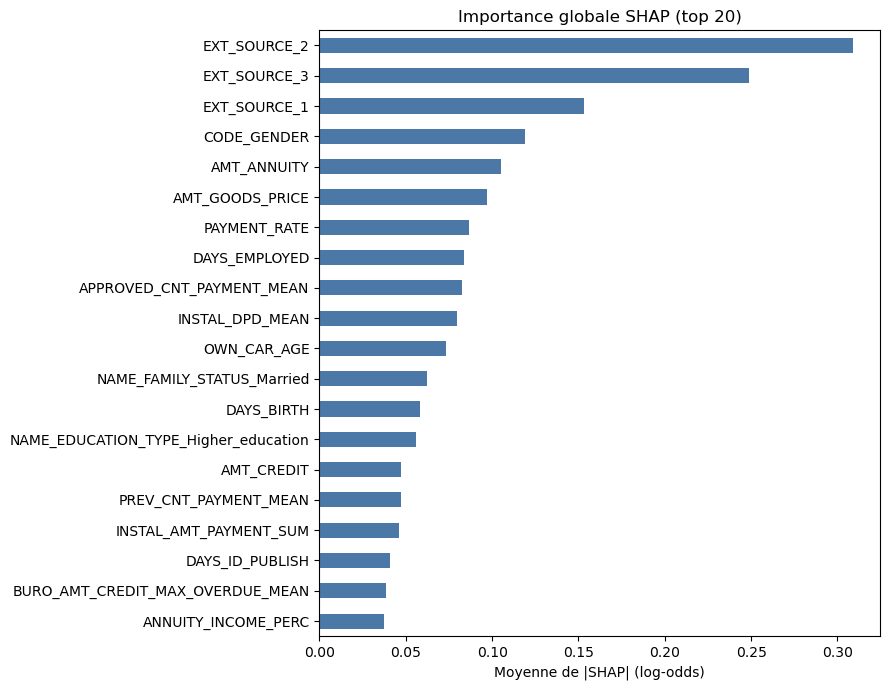

In [4]:
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X_s.columns)
importance = importance.sort_values(ascending=False)
importance.rename("shap_moyen_abs").to_csv(MODEL_DIR / "shap_importance.csv")

fig, ax = plt.subplots(figsize=(9, 7))
importance.head(20)[::-1].plot.barh(ax=ax, color="#4C78A8")
ax.set(title="Importance globale SHAP (top 20)", xlabel="Moyenne de |SHAP| (log-odds)")
plt.tight_layout()
plt.savefig(FIG_DIR / "P6_03_shap_importance_globale.png", dpi=150)
plt.show()

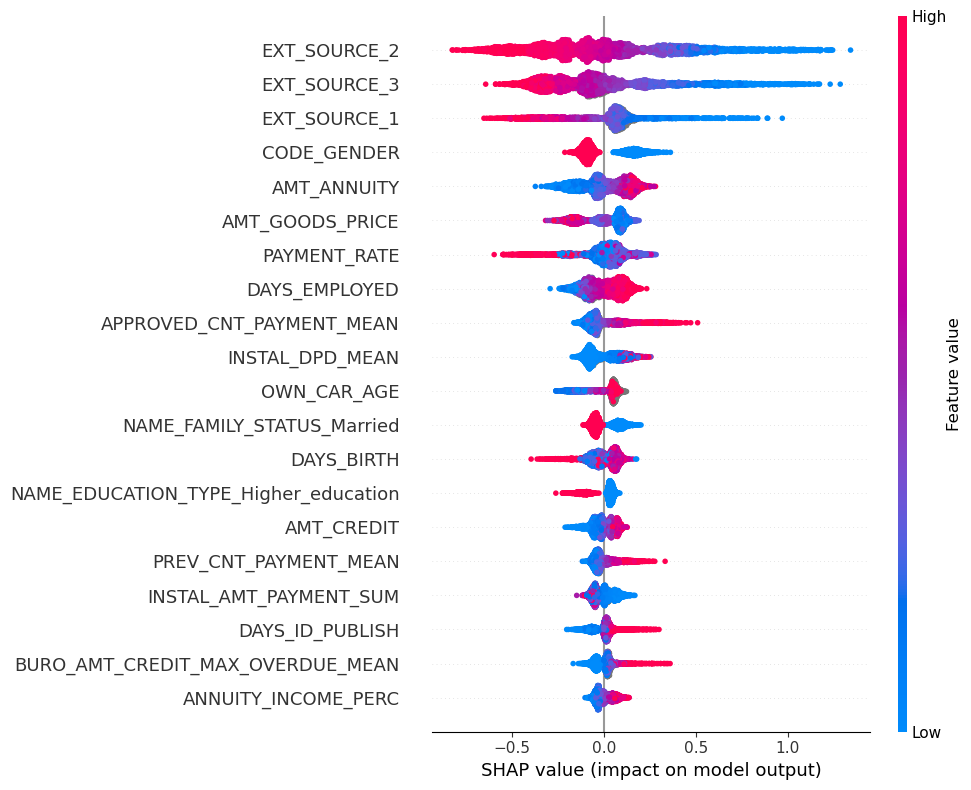

In [5]:
shap.summary_plot(shap_values, X_s, max_display=20, show=False)
plt.gcf().set_size_inches(10, 8)
plt.tight_layout()
plt.savefig(FIG_DIR / "P6_03_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture** : repérer les variables qui reviennent (scores externes `EXT_SOURCE_*`,
durée de crédit, ratios annuité/revenu, comportement de paiement des échéances…) et
vérifier que le **sens** est cohérent métier. Par exemple, un `EXT_SOURCE` élevé doit
*réduire* le risque.

### 3. Explication locale d'un client

Fonction qui produit, pour un client, ses principaux facteurs de risque et de
protection : c'est exactement ce qu'affichera le dashboard, en langage non technique.

In [6]:
def explain_client(position, top=5):
    """Retourne score, décision et facteurs principaux pour la ligne ``position``."""
    contrib = pd.Series(shap_values[position], index=X_s.columns)
    values = X_s.iloc[position]
    table = pd.DataFrame({"valeur": values, "impact": contrib})
    risk = table[table["impact"] > 0].nlargest(top, "impact")
    safe = table[table["impact"] < 0].nsmallest(top, "impact")
    return {
        "client": X_s.index[position],
        "probabilite_defaut": float(proba_s[position]),
        "decision": "REFUS" if proba_s[position] >= THRESHOLD else "ACCORD",
        "facteurs_de_risque": risk,
        "facteurs_protecteurs": safe,
    }


pos_risky = int(np.argmax(proba_s))
pos_safe = int(np.argmin(proba_s))
for label, pos in (("CLIENT À RISQUE ÉLEVÉ", pos_risky), ("CLIENT À RISQUE FAIBLE", pos_safe)):
    result = explain_client(pos)
    print(f"=== {label} : {result['client']} ===")
    print(f"Probabilité de défaut : {result['probabilite_defaut']:.1%} -> {result['decision']}")
    print("\nFacteurs qui augmentent le risque :")
    print(result["facteurs_de_risque"].round(3))
    print("\nFacteurs qui réduisent le risque :")
    print(result["facteurs_protecteurs"].round(3), "\n")

=== CLIENT À RISQUE ÉLEVÉ : 159954 ===
Probabilité de défaut : 73.3% -> REFUS

Facteurs qui augmentent le risque :
                              valeur  impact
EXT_SOURCE_2                   0.002   0.873
EXT_SOURCE_1                   0.089   0.705
DAYS_ID_PUBLISH              -66.000   0.189
CC_CNT_DRAWINGS_CURRENT_MEAN  17.000   0.181
INSTAL_DPD_MEAN                0.800   0.145

Facteurs qui réduisent le risque :
                                       valeur  impact
DAYS_EMPLOYED                         -3822.0  -0.113
NAME_FAMILY_STATUS_Married                1.0  -0.069
DAYS_REGISTRATION                    -10620.0  -0.050
AMT_CREDIT                           250272.0  -0.047
WEEKDAY_APPR_PROCESS_START_SATURDAY       1.0  -0.042 

=== CLIENT À RISQUE FAIBLE : 167623 ===
Probabilité de défaut : 0.2% -> ACCORD

Facteurs qui augmentent le risque :
                                        valeur  impact
NAME_FAMILY_STATUS_Married        0.000000e+00   0.083
ACTIVE_AMT_CREDIT_SUM_SUM  

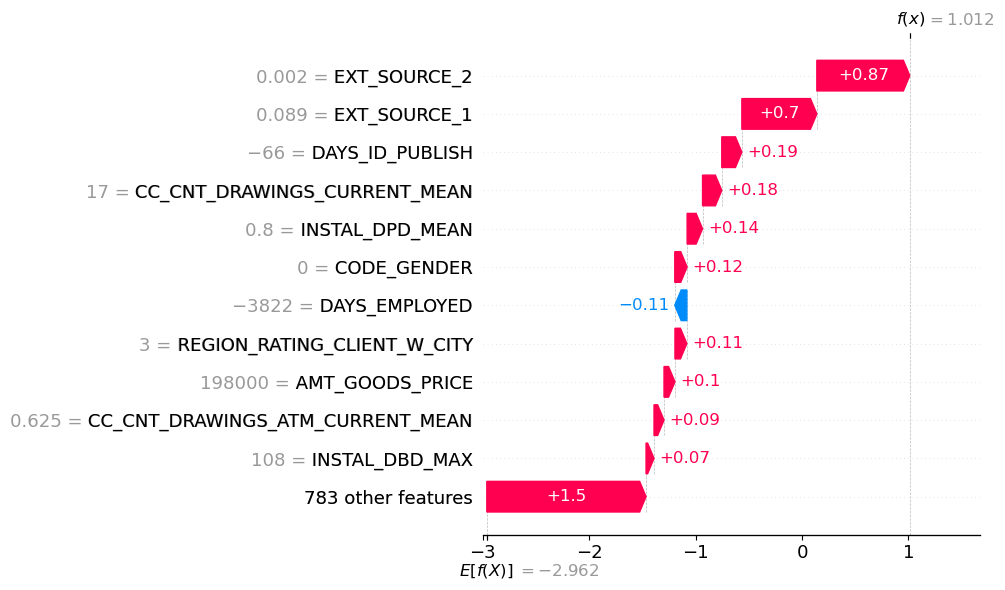

In [7]:
explanation = shap.Explanation(
    values=shap_values[pos_risky],
    base_values=base_value,
    data=X_s.iloc[pos_risky].values,
    feature_names=list(X_s.columns),
)
shap.plots.waterfall(explanation, max_display=12, show=False)
plt.gcf().set_size_inches(10, 6)
plt.tight_layout()
plt.savefig(FIG_DIR / "P6_03_shap_waterfall_client.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Cohérence : l'importance du modèle vs SHAP

Les deux classements doivent globalement concorder. Un désaccord fort signalerait des
variables corrélées entre elles (l'importance « gain » se répartit mal entre elles).

In [8]:
gain = pd.read_csv(MODEL_DIR / "feature_importance.csv", index_col=0).squeeze("columns")
common = importance.index.intersection(gain.index)
rho = importance[common].rank().corr(gain[common].rank())
print(f"Corrélation de rang (gain vs SHAP) : {rho:.2f}")
top_g = set(gain.nlargest(20).index)
top_s = set(importance.nlargest(20).index)
print(f"Variables communes au top 20 : {len(top_g & top_s)} / 20")

Corrélation de rang (gain vs SHAP) : 0.97
Variables communes au top 20 : 14 / 20


**Prochaine étape** : API FastAPI (`/predict` renvoie score, décision et facteurs) puis
dashboard Streamlit. Les fichiers `models/shap_importance.csv` et les figures
`P6_03_*.png` alimentent la note méthodologique et la présentation.